# 04 · Staffing model: how many people per hour, and how to roster them

**Data:** **[SYNTHETIC]** one-year 20× scale-up of the export (46,598 tickets, 202,172 agent work items), calibrated to the **[REAL]** 2023 export (2,330 tickets) · **[ASSUMPTION]** handle time, shrinkage, occupancy cap, SLA goal and today's roster (`config.yaml`).

In [1]:
import json, pandas as pd, plotly.io as pio
pio.renderers.default = "notebook_connected+png"     # interactive in HTML export, static PNG fallback for GitHub
pio.renderers["png"].width, pio.renderers["png"].height = 1000, None
from support_ops import charts as C
from support_ops.data import load_processed, load_tickets
from support_ops.config import load_config, REPO_ROOT
kn = json.load(open(REPO_ROOT / "reports" / "key_numbers.json"))
cfg = load_config()

# notebook 04 additions
import math
import numpy as np
from support_ops import erlang, roster, staffing, synth
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)


def check(value, key, d=4):
    """Recomputed value must equal reports/key_numbers.json to d decimals (the precision it is stored at)."""
    assert abs(value - kn[key]) <= 0.5 * 10 ** -d + 1e-9, f"{key}: recomputed {value!r} vs key_numbers {kn[key]!r}"
    return value


def P(x, d=1):
    """Share -> percentage text, e.g. 0.8761 -> '87.6%'."""
    return f"{100 * x:.{d}f}%"

## TL;DR

- **[SYNTHETIC] A desk at 20× the export's volume needs about 23 FTE** (115 eight-hour shifts a week) when every hour is staffed with whole people. Pure workload maths without rounding gives 18.8 FTE; handle time ±30% moves the answer to 16–28 FTE. This is a planning scenario (a 23-FTE desk in the 20× scenario), not a measurement of today's team.
- **Same 23 FTE, re-rostered from weekday-weighted (today's roster, assumed) to workload-matched:** simulated response SLA 85.8% → 87.6% under the optimistic rule and 82.6% → 84.7% under the conservative rule. Over 5 independent synthetic years the gain is +1.5 to +2.0 points (optimistic) and +1.3 to +1.9 (conservative), and the ranking of rosters never changes.
- **Hiring instead** (keep today's roster, add 7 weekend shifts = 1.4 FTE, 2 whole hires, €94k in year one) buys only +0.1 to +0.2 (optimistic) / +1.1 to +1.4 (conservative) points more than re-rostering.
- **No roster beats the 87.8% process ceiling** set by slow and missed pickups in the real data, and no roster moves resolution SLA, the SLA that fell.
- **The roster gain is conditional** on today's roster being weekday-weighted and on weekend follow-up work being done when it arises. If weekend follow-ups wait until Monday, the gain swings between -2.1 and +2.3 points: not robust. The workload-matched roster meets the staffing goal up to +25% volume (+50% with base-case deflection, the top of the tested range).

In [2]:
print(f"FTE needed, 20x scenario: {kn['staff_fte_current']} ({kn['staff_weekly_shifts']} shifts/week); "
      f"no-rounding workload maths {kn['staff_fte_continuous']:.1f}; handle time -/+30%: "
      f"{kn['sens_fte_aht_low']}-{kn['sens_fte_aht_high']}")
print(f"Response SLA, weekday-weighted -> workload-matched: optimistic {P(kn['staff_sl_today_by_day'])} -> "
      f"{P(kn['staff_sl_proposed'])}, conservative {P(kn['staff_sl_sum_today_by_day'])} -> {P(kn['staff_sl_sum_proposed'])}")
print(f"Gain over {kn['rep_n']} synthetic years: +{kn['rep_gain_pp_vs_by_day_min']:.1f} to "
      f"+{kn['rep_gain_pp_vs_by_day_max']:.1f} pts (optimistic), +{kn['rep_gain_pp_vs_by_day_sum_min']:.1f} to "
      f"+{kn['rep_gain_pp_vs_by_day_sum_max']:.1f} (conservative); ranking stable: "
      f"{kn['rep_ranking_stable'] and kn['rep_ranking_stable_sum']}")
print(f"Hire instead: +{kn['staff_hire_extra_shifts_by_day']} weekend shifts = {kn['staff_hire_extra_fte_equiv_by_day']:.1f} FTE "
      f"({kn['staff_hire_extra_fte_by_day']} whole hires), year-1 cost EUR {kn['bc_hire_first_year_eur']:,}; "
      f"extra vs re-roster +{kn['rep_hire_minus_reroster_pp_min']:.1f} to +{kn['rep_hire_minus_reroster_pp_max']:.1f} (opt.), "
      f"+{kn['rep_hire_minus_reroster_pp_sum_min']:.1f} to +{kn['rep_hire_minus_reroster_pp_sum_max']:.1f} (cons.)")
print(f"Process ceiling: {P(kn['staff_process_ceiling'])}")
print(f"Stress test (weekend follow-ups wait until Monday): gain {kn['deferred_gain_pp_vs_by_day_sum']:+.1f} (cons.) "
      f"to {kn['deferred_gain_pp_vs_by_day']:+.1f} (opt.) pts")
print(f"Staffing goal holds up to +{kn['growth_holds_until_no_deflection']:.0%} volume; with base deflection "
      f"+{kn['growth_holds_until_with_deflection']:.0%} (top of tested range: {kn['growth_holds_until_with_deflection_is_range_end']})")

FTE needed, 20x scenario: 23 (115 shifts/week); no-rounding workload maths 18.8; handle time -/+30%: 16-28
Response SLA, weekday-weighted -> workload-matched: optimistic 85.8% -> 87.6%, conservative 82.6% -> 84.7%
Gain over 5 synthetic years: +1.5 to +2.0 pts (optimistic), +1.3 to +1.9 (conservative); ranking stable: True
Hire instead: +7 weekend shifts = 1.4 FTE (2 whole hires), year-1 cost EUR 94,000; extra vs re-roster +0.1 to +0.2 (opt.), +1.1 to +1.4 (cons.)
Process ceiling: 87.8%
Stress test (weekend follow-ups wait until Monday): gain -2.1 (cons.) to +2.3 (opt.) pts
Staffing goal holds up to +25% volume; with base deflection +50% (top of tested range: True)


## Question

From the Director's request (*"How many people do we need in each time slot? Is there a way to fix this without adding people?"*), as scoped in `docs/01_request_and_scope.md`:

- **Q5.** For each hour of the week, how many agents are needed to hit the SLA goal, given arrivals and handle time? How does that compare with today's roster?
- **Q6a.** How much response SLA does re-rostering the same headcount buy?
- **Q7, staffing part.** What would hiring buy instead, and how much volume growth can the same team absorb before headcount is needed?

What this notebook cannot answer: whether today's real team is short-staffed. We have neither the real roster nor the real headcount. The real-data tests in notebook 03 are the evidence on that, and they show no capacity signal.

## Data

Every table is **[SYNTHETIC]** except `fct_tickets` and `kpi_by_dimension` (**[REAL]**). All were written by `python run.py` (`support_ops.pipeline.run`); the function that produced each one is listed. This notebook re-computes the cheap steps (Erlang C, the hourly requirement, the roster optimisation) and loads the simulation outputs instead of re-simulating.

Numbers in the text come from `reports/key_numbers.json`; code cells print them and assert that the recomputed values match. A few supporting numbers that are not headline numbers are computed in the cell just above the text that quotes them.

In [3]:
tables = {
    "fct_tickets": ("REAL", "data.build_fct_tickets (sql/00_fct_tickets.sql)"),
    "kpi_by_dimension": ("REAL", "kpis.build_kpis (sql/02_kpi_by_dimension.sql)"),
    "synth_tickets": ("SYNTHETIC", "synth.generate_tickets"),
    "kpi_by_dimension_synth": ("SYNTHETIC", "same SQL on the synthetic tickets"),
    "synth_work_items": ("SYNTHETIC", "synth.build_work_items"),
    "staff_demand": ("SYNTHETIC", "staffing.demand_by_how"),
    "staff_requirement": ("SYNTHETIC", "staffing.requirement"),
    "staff_coverage": ("SYNTHETIC", "staffing.capacity_plan"),
    "staff_hire_options": ("SYNTHETIC", "staffing.capacity_plan"),
    "staff_sim_summary": ("SYNTHETIC", "staffing.capacity_plan -> simulate_roster"),
    "staff_sim_response": ("SYNTHETIC", "staffing.capacity_plan -> simulate_roster"),
    "staff_sim_hourly": ("SYNTHETIC", "staffing.capacity_plan -> simulate_roster"),
    "staff_sim_summary_deferred": ("SYNTHETIC", "staffing.capacity_plan(follow_up_timing='weekdays')"),
    "staff_replications": ("SYNTHETIC", "business_case.replicate_rosters"),
    "staff_sensitivity": ("SYNTHETIC", "staffing.sensitivity"),
    "staff_growth": ("SYNTHETIC", "business_case.simulate_growth"),
}
D = {name: (load_tickets() if name == "fct_tickets" else load_processed(name)) for name in tables}
pd.DataFrame([{"table": n, "source": s, "produced by": f, "rows": len(D[n])} for n, (s, f) in tables.items()])

,table,source,produced by,rows
0,fct_tickets,REAL,data.build_fct_tickets (sql/00_fct_tickets.sql),2330
1,kpi_by_dimension,REAL,kpis.build_kpis (sql/02_kpi_by_dimension.sql),38
2,synth_tickets,SYNTHETIC,synth.generate_tickets,46598
3,kpi_by_dimension_synth,SYNTHETIC,same SQL on the synthetic tickets,38
4,synth_work_items,SYNTHETIC,synth.build_work_items,202172
5,staff_demand,SYNTHETIC,staffing.demand_by_how,168
6,staff_requirement,SYNTHETIC,staffing.requirement,168
7,staff_coverage,SYNTHETIC,staffing.capacity_plan,168
8,staff_hire_options,SYNTHETIC,staffing.capacity_plan,3
9,staff_sim_summary,SYNTHETIC,staffing.capacity_plan -> simulate_roster,7


In [4]:
st = cfg["staffing"]                                   # ASSUMPTIONS (config.yaml, documented in docs/assumptions.md)
pd.Series({k: st[k] for k in ["live_channels", "live_target_min", "async_target_min", "sl_goal", "max_occupancy",
                              "shrinkage", "handle_time_min", "handle_time_cv", "min_agents_per_pool",
                              "shift_length_h", "shift_starts", "shifts_per_fte_week"]},
          name="config.yaml -> staffing").to_frame()

,config.yaml -> staffing
live_channels,"[Chat, Phone]"
live_target_min,2
async_target_min,60
sl_goal,0.9
max_occupancy,0.85
shrinkage,0.3
handle_time_min,"{'chat_first': 12, 'phone_first': 10, 'email_f..."
handle_time_cv,0.8
min_agents_per_pool,1
shift_length_h,8


## Method

The model answers *"how many people per hour does a desk like this need, and how should they be spread?"* in the steps below. Each step is re-run or loaded in Results.

**1 · Scale up [SYNTHETIC].** At about 0.3 tickets per hour no queue ever forms in the export, so Erlang C has nothing to work with. `synth.generate_tickets` builds one synthetic year at 20× volume. Arrivals follow the export's weekday rates and its (3-hour smoothed) hour-of-day profile. Every other attribute — channel, topic, interactions, resolution outcome, CSAT and the real first-response delay — is copied from a real ticket created in the same month.

**2 · Work items [SYNTHETIC + ASSUMPTION].** `synth.build_work_items` turns each ticket into agent work: a first touch (chat/phone = *live*, the customer is waiting; email = *async*) plus one follow-up touch per extra agent interaction, spread evenly over the ticket's life. Handle time is not in the export, so we assume 12 / 10 / 8 minutes for a first chat / phone / email touch and 6 minutes per follow-up (lognormal, coefficient of variation 0.8).

**3 · Erlang C.** For one hour with arrival rate $\lambda$ (contacts per hour) and average handle time $\mathrm{AHT}$ (minutes), the traffic intensity in Erlangs is

$$A = \frac{\lambda \cdot \mathrm{AHT}}{60}$$

With $N > A$ agents, the probability that a contact has to wait is

$$C(N, A) = \frac{\dfrac{A^N}{N!} \cdot \dfrac{N}{N-A}}{\displaystyle\sum_{k=0}^{N-1} \frac{A^k}{k!} + \frac{A^N}{N!} \cdot \frac{N}{N-A}}$$

and the service level (share answered within $t$ minutes), the average wait and the occupancy are

$$\mathrm{SL}(N, A, t) = 1 - C(N, A)\, e^{-(N-A)\, t / \mathrm{AHT}} \qquad \mathrm{ASA} = \frac{C(N, A) \cdot \mathrm{AHT}}{N - A} \qquad \text{occupancy} = \frac{A}{N}$$

Erlang C assumes Poisson arrivals, exponential handle times, no abandonment, a steady state within each hour and first-come-first-served. `support_ops.erlang` computes $C(N, A)$ with the numerically stable Erlang B recursion instead of factorials and follows the `pyworkforce` conventions; both are checked in Results §2.

> **How to read this.** $A$ is how many agents would be busy on average. Erlang C asks for a few more than $A$ because contacts arrive in random bursts. Each extra agent cuts waiting by less than the one before: diminishing returns.

**4 · Requirement rule (per hour $h$ of the 168-hour week).** Live work may interrupt email and follow-up work, so live contacts see the whole team. The productive agents needed are the largest of three numbers, then grossed up for shrinkage and rounded **once**, to whole people (`staffing.requirement`):

$$N_h = \max\left( N^{\mathrm{live}}_h,\ \frac{A^{\mathrm{live}}_h + A^{\mathrm{async}}_h}{\text{max occupancy}},\ 1 \right) \qquad \text{scheduled}_h = \left\lceil \frac{N_h}{1 - \text{shrinkage}} \right\rceil$$

- $N^{\mathrm{live}}_h$ is the smallest whole number of agents with $\mathrm{SL}(N, A^{\mathrm{live}}_h, 2\ \text{min}) \ge 0.90$ (Erlang C, 2-minute live target, 90% goal);
- the workload term keeps agents busy no more than 85% of the time (it is fractional, so it is not rounded on its own);
- 1 = at least one person on duty every hour (24/7 cover);
- shrinkage = 30% of scheduled time lost to breaks, meetings, training and absence.

Rounding once matters: rounding agents up and then people up again would add a person in many hours.

**5 · Roster (integer programme).** A shift is a start time (00, 08, 12 or 16 h) on a day of the week: 28 shift types of 8 hours. Let $x_j$ be the number of people starting shift $j$, and $a_{hj} = 1$ if shift $j$ covers hour $h$. The cheapest roster solves (`roster.optimize_min_shifts`, `scipy.optimize.milp` with HiGHS)

$$\min_{x} \sum_j x_j \quad \text{subject to} \quad \sum_j a_{hj}\, x_j \ \ge\ \text{scheduled}_h \ \text{ for all 168 hours}, \qquad x_j \in \{0, 1, 2, \dots\}$$

Headcount is that many shifts ÷ 5 shifts per FTE, rounded up. With headcount fixed, `roster.optimize_fixed_budget` then spreads exactly $5 \times \text{FTE}$ shifts so that the worst-covered hour is as well covered as possible:

$$\max_{x,\, t}\ t \quad \text{subject to} \quad \sum_j a_{hj}\, x_j \ \ge\ t \cdot \text{scheduled}_h \ \ \forall h, \qquad \sum_j x_j = 5 \cdot \text{FTE}, \qquad \sum_{j \in \text{day } d} x_j \le \text{FTE} \ \ \forall d$$

(at most one shift per person per day; ties go to busier hours). The result is the **proposed, workload-matched roster**.

**6 · Today's roster is not in the data.** We compare the proposed roster with three hypotheses that use the **same number of shifts**, as 3 × 8-hour shifts starting 00/08/16 (`roster.HYPOTHESES`): **weekday-weighted** (the baseline assumption: each day's headcount proportional to that day's *new-ticket* count, split equally over its three shifts), **flat 24/7** (the same headcount on every shift), and **day-weighted** (daily headcount proportional to volume, 47% of each day's shifts on 08–16). The **hire** alternative keeps today's roster and adds the fewest shifts that close every gap (`roster.extra_shifts_to_cover`).

**7 · Simulation and the two response-time rules.** Erlang C treats every hour as a separate steady state. The discrete-event simulation (`support_ops.simulation`, run by `staffing.simulate_roster`) replays the synthetic year item by item: backlogs carry over from hour to hour, handle times are lognormal, live contacts pre-empt email work, and the agents available each hour are scheduled × (1 − shrinkage), rounded at random. It is checked against Erlang C in `tests/test_simulation.py` (within a point on textbook cases).

A customer's first-response time combines the **queue wait** $W$ (no agent free; staffing controls it) and the **pickup delay** $D$ copied from the real seed ticket (how fast agents picked work up when they were free; process, not staffing). We do not know how the two combine, so every result is shown under two rules:

$$\text{optimistic: } R = \max(W, D) \qquad\qquad \text{conservative: } R = W + D \qquad\qquad \text{on time if } R \le \text{target}$$

The **process ceiling** is the share of tickets with $D \le \text{target}$: the response SLA with zero queueing. No roster can beat it.

> **How to read this.** The optimistic rule assumes waiting for an agent and slow pickup overlap: a ticket is late only if one of them alone is too long. The conservative rule assumes they add up. The truth lies in between, so a conclusion is only solid if it holds under both rules.

**8 · Robustness.** (a) The roster comparison re-run on 5 independent synthetic years; (b) a stress test where weekend follow-ups wait until Monday; (c) one-at-a-time sensitivity of the FTE answer; (d) volume growth with the proposed roster held fixed.

## Results

### 1. Why scale up, and is the synthetic year faithful?

Erlang C needs a stable arrival rate per hour. The export has 6.42 tickets per calendar day, about 0.3 per hour. The cell below counts the real tickets in every hour-of-week slot of every week, then compares the synthetic year's daily volume with 20 × the real daily rate.

In [5]:
fct = D["fct_tickets"]
days = (fct["created_date"].max() - fct["created_date"].min()).days + 1
print(f"[REAL] {len(fct):,} tickets over {days} days = {len(fct) / (days * 24):.2f} tickets per hour")
f2 = fct.assign(week=fct["created_at"].dt.to_period("W-SUN"), how=(fct["created_dow"] - 1) * 24 + fct["created_hour"])
grid = pd.MultiIndex.from_product([pd.period_range(f2["week"].min(), f2["week"].max(), freq="W-SUN"), range(168)],
                                  names=["week", "how"])
per_cell = f2.groupby(["week", "how"]).size().reindex(grid, fill_value=0)
print(f"[REAL] {len(per_cell):,} week x hour-of-week slots: {(per_cell == 0).mean():.0%} empty, "
      f"{(per_cell <= 1).mean():.0%} with 0-1 tickets, busiest slot {per_cell.max()} tickets")

syn = D["synth_tickets"]
open_days = pd.date_range("2023-01-01", "2023-12-31").difference(pd.to_datetime(synth.HOLIDAYS_2023))
n_days = pd.Series(open_days.day_of_week + 1).value_counts().sort_index()      # non-holiday days per weekday
cal = pd.DataFrame({"real per day": synth.daily_rate_by_weekday(fct),
                    "synthetic per day": syn.groupby("created_dow").size() / n_days})
cal["synthetic / (20 x real)"] = cal["synthetic per day"] / (cfg["scenario"]["scale_factor"] * cal["real per day"])
cal.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
print(f"[SYNTHETIC] {check(len(syn), 'synth_tickets', 0):,} tickets ({len(syn) / 365:.1f} per day), "
      f"{check(len(D['synth_work_items']), 'synth_work_items', 0):,} work items")
cal.round(2)

[REAL] 2,330 tickets over 363 days = 0.27 tickets per hour
[REAL] 8,736 week x hour-of-week slots: 77% empty, 97% with 0-1 tickets, busiest slot 4 tickets
[SYNTHETIC] 46,598 tickets (127.7 per day), 202,172 work items


,real per day,synthetic per day,synthetic / (20 x real)
Mon,8.04,160.63,1.00
Tue,7.39,149.29,1.01
Wed,8.44,166.35,0.99
Thu,7.10,143.37,1.01
Fri,7.38,146.17,0.99
Sat,3.17,63.87,1.01
Sun,3.72,75.30,1.01


**Reading the output:** at the export's volume 77% of week × hour slots are empty and 97% hold at most one ticket, so no queue ever forms and the export alone cannot support an hourly staffing model. The synthetic year reproduces 20 × the real rate on every weekday to within 1.5% (Poisson noise). Next, the same KPI SQL as notebook 02 (`sql/02_kpi_by_dimension.sql`) is re-run on the synthetic tickets to compare the mix.

Largest channel/topic/priority share gap: 0.51 pts | resolution SLA: real 66.4%, synthetic 66.3%


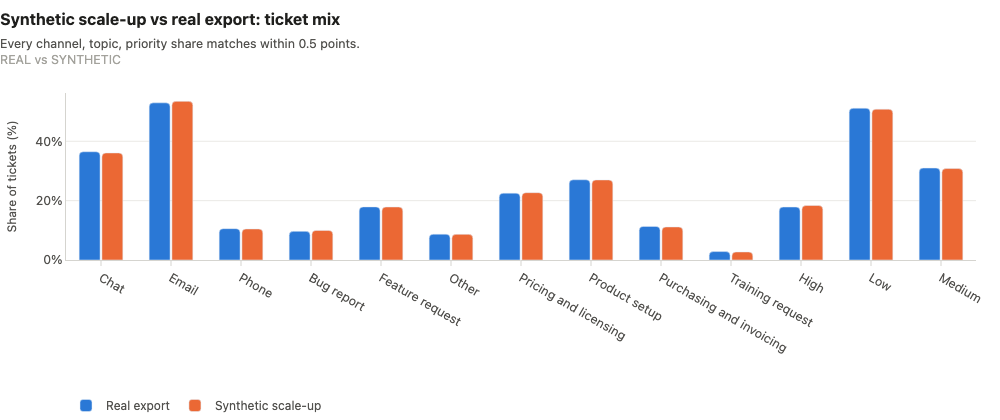

In [6]:
from support_ops.config import processed_path
from support_ops.sql import run_sql_file
synth_bydim = run_sql_file("02_kpi_by_dimension.sql",
                           {"fct_tickets_path": str(processed_path("synth_fct_tickets.parquet"))})
pd.testing.assert_frame_equal(synth_bydim, D["kpi_by_dimension_synth"], check_dtype=False)   # = cached table
mix = (D["kpi_by_dimension"].merge(synth_bydim, on=["dimension", "segment"], suffixes=("_real", "_synth"))
       .query("dimension in ['channel', 'topic', 'priority']"))
max_gap_pp = check(100 * (mix["share_of_tickets_real"] - mix["share_of_tickets_synth"]).abs().max(),
                   "synth_max_mix_gap_pp", 2)
res_sla_synth = check(syn["resolution_sla_met"].mean(), "synth_resolution_sla")
print(f"Largest channel/topic/priority share gap: {max_gap_pp:.2f} pts | resolution SLA: real "
      f"{P(kn['resolution_sla_2023'])}, synthetic {P(res_sla_synth)}")
C.fig_synth_validation(D["kpi_by_dimension"], synth_bydim)

**What this shows:** every channel, topic and priority share in the synthetic year is within 0.5 points of the real export, and resolution SLA is 66.4% real vs 66.3% synthetic, because each synthetic ticket copies a real ticket from the same month. The scale-up adds volume, not new behaviour.

### 2. Erlang C: unit check and teaching curve

Two checks on `support_ops.erlang` (both also run in `tests/test_erlang.py`). First, the recursion in the code must equal the factorial formula from the Method section. Second, the code must reproduce the worked example in the `pyworkforce` ErlangC documentation: 100 contacts per 30 minutes, 3-minute handle time, answer within 20 seconds, 80% goal, 85% max occupancy, 30% shrinkage → 14 agents, 20 scheduled, service level ≈ 0.888, occupancy ≈ 0.714.

In [7]:
def erlang_c_textbook(n, a):
    """Factorial form of C(N, A) from the Method section (fine for small N)."""
    top = a ** n / math.factorial(n) * n / (n - a)
    return top / (sum(a ** k / math.factorial(k) for k in range(n)) + top)

for n, a in [(2, 0.5), (5, 3.2), (14, 10.0), (20, 17.5)]:
    assert abs(erlang.erlang_c(n, a) - erlang_c_textbook(n, a)) < 1e-10
print("Erlang B recursion = factorial formula on 4 test cases")

lam, aht, target = 100 * 2, 3.0, 20 / 60                # pyworkforce example: per hour, minutes, minutes
a = erlang.traffic_intensity(lam, aht)
n = erlang.required_agents(lam, aht, target, sl_goal=0.80, max_occupancy=0.85)
sl = erlang.service_level(n, a, aht, target)
print(f"pyworkforce example: A = {a:.1f} Erlangs -> {n} agents -> {erlang.scheduled_agents(n, 0.30)} scheduled "
      f"after 30% shrinkage; service level {sl:.3f}, occupancy {a / n:.3f}")
assert (a, n, erlang.scheduled_agents(n, 0.30)) == (10.0, 14, 20)
assert abs(sl - 0.888) < 0.001 and abs(a / n - 0.714) < 0.001
pd.DataFrame([{"agents N": k, "P(wait) C(N,A)": erlang.erlang_c(k, a),
               "answered within 20 s": erlang.service_level(k, a, aht, target),
               "occupancy A/N": a / k, "average wait (s)": 60 * erlang.asa_min(k, a, aht)}
              for k in range(11, 17)]).round(3)

Erlang B recursion = factorial formula on 4 test cases
pyworkforce example: A = 10.0 Erlangs -> 14 agents -> 20 scheduled after 30% shrinkage; service level 0.888, occupancy 0.714


,agents N,"P(wait) C(N,A)",answered within 20 s,occupancy A/N,average wait (s)
0,11,0.682,0.390,0.909,122.781
1,12,0.449,0.640,0.833,40.445
2,13,0.285,0.796,0.769,17.116
3,14,0.174,0.888,0.714,7.836
4,15,0.102,0.941,0.667,3.674
5,16,0.057,0.971,0.625,1.720


**Reading the table:** the 80% goal is first met at 14 agents, as in the pyworkforce documentation. Each further agent adds less service level than the one before and lowers occupancy (agents are busy a smaller share of the time).

The same formula on a busy hour of the 20× scenario: about 3 live contacts an hour at 11.5 minutes each (the average live handle time in the synthetic work items, printed below).

Live handle time in the synthetic work items: 11.5 min; live contacts per hour: mean 2.5, max 3.8


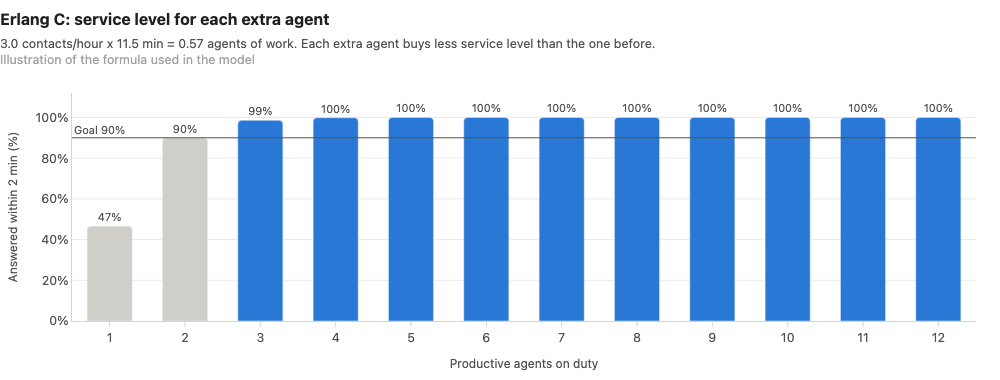

In [8]:
dem = D["staff_demand"]
print(f"Live handle time in the synthetic work items: {dem['aht_live_min'].iloc[0]:.1f} min; live contacts per hour: "
      f"mean {dem['live_per_hour'].mean():.1f}, max {dem['live_per_hour'].max():.1f}")
C.fig_erlang_curve(3.0, 11.5, st["live_target_min"], st["sl_goal"])

**What this shows:** live work in a busy hour is about 0.57 Erlangs: not even one agent busy on average. Two agents answer 89.98% within 2 minutes, just under the 90% goal; a third lifts that to 98.6%. This is why the 2-minute live target rarely sets headcount here. Total workload does (next section).

### 3. Hourly demand and the requirement

`staff_demand` holds, for each of the 168 hours of the week, the average number of live contacts and async items (email first replies and follow-ups) arriving on a non-holiday day of the synthetic year, with their average handle times. We re-run `staffing.requirement` on it and check that it reproduces the cached `staff_requirement`.

In [9]:
demand = D["staff_demand"]
req = staffing.requirement(demand, st)
assert (req["scheduled_required"].to_numpy() == D["staff_requirement"]["scheduled_required"].to_numpy()).all()
binding = req["binding"].value_counts()
check(binding.get("workload / occupancy cap", 0), "staff_hours_binding_workload", 0)
check(binding.get("live response", 0), "staff_hours_binding_live", 0)
check(req["scheduled_required"].max(), "staff_peak_scheduled", 0)
check(req["scheduled_required"].min(), "staff_min_scheduled", 0)
print("What sets the requirement (hours of the week):", binding.to_dict())
by_day = (demand.groupby("dow_name", sort=False)[["tickets_per_hour", "live_per_hour", "async_per_hour", "erlangs_total"]]
          .mean()
          .join(req.groupby("dow_name", sort=False)["scheduled_required"].agg(["min", "median", "max"])
                .add_prefix("people needed per hour: ")))
by_day.round(2)

What sets the requirement (hours of the week): {'workload / occupancy cap': 158, 'live response': 10}


,tickets_per_hour,live_per_hour,async_per_hour,erlangs_total,people needed per hour: min,people needed per hour: median,people needed per hour: max
dow_name,,,,,,,
Mon,6.69,3.12,20.65,2.76,5,5.0,6
Tue,6.22,2.85,22.93,2.95,5,5.0,6
Wed,6.93,3.25,24.38,3.17,6,6.0,6
Thu,5.97,2.74,23.37,2.97,5,6.0,6
Fri,6.09,2.84,23.23,2.98,5,5.0,6
Sat,2.66,1.25,16.81,2.00,3,4.0,5
Sun,3.14,1.43,14.31,1.77,3,3.0,4


**Reading the table:** weekday hours need 5–6 people on shift, weekend hours 3–5. Weekends get only 45% of the weekday new-ticket rate, but 64% of the weekday workload (Erlangs): follow-up work on tickets opened during the week keeps arriving at weekends.

One hour in detail, the busiest hour of the week:

In [10]:
h = int(demand["erlangs_total"].idxmax())
d = demand.loc[h]
a_live, a_async = d.live_per_hour * d.aht_live_min / 60, d.async_per_hour * d.aht_async_min / 60
n_live = erlang.required_agents(d.live_per_hour, d.aht_live_min, st["live_target_min"], st["sl_goal"])
n_work = (a_live + a_async) / st["max_occupancy"]
n = max(n_live, n_work, st["min_agents_per_pool"])
walk = pd.Series({
    "live contacts per hour": d.live_per_hour, "live handle time (min)": d.aht_live_min, "A_live (Erlangs)": a_live,
    "async items per hour": d.async_per_hour, "async handle time (min)": d.aht_async_min, "A_async (Erlangs)": a_async,
    "N_live: Erlang C, 90% within 2 min": n_live, "workload: (A_live + A_async) / 0.85": n_work,
    "N = max(N_live, workload, 1)": n,
    f"scheduled = ceil(N / (1 - {st['shrinkage']}))": erlang.scheduled_agents(n, st["shrinkage"]),
}, name=f"{d.dow_name} {int(d.hour):02d}:00")
assert walk.iloc[-1] == req.loc[h, "scheduled_required"]
walk.round(2).to_frame()

,Wed 16:00
live contacts per hour,3.56
live handle time (min),11.51
A_live (Erlangs),0.68
async items per hour,25.58
async handle time (min),6.28
A_async (Erlangs),2.68
"N_live: Erlang C, 90% within 2 min",3.00
workload: (A_live + A_async) / 0.85,3.95
"N = max(N_live, workload, 1)",3.95
scheduled = ceil(N / (1 - 0.3)),6.00


**Reading the walk-through:** at the busiest hour (Wed 16:00) live work alone needs 3 agents for the 2-minute target, but total workload needs 3.95 productive agents to stay under 85% occupancy. Workload binds, and 30% shrinkage turns that into 6 people on shift. Across the week, workload binds in 158 of 168 hours and the live target in 10.

### 4. The workload-matched roster (integer programme)

First the cheapest set of 8-hour shifts that covers every hour, which sets headcount. The bridge below shows where the person-hours between pure workload maths and the roster come from.

In [11]:
required = req["scheduled_required"].to_numpy()
cheapest = roster.optimize_min_shifts(required, st["shift_starts"])       # min sum(x) s.t. coverage >= requirement
n_shifts = int(cheapest["agents"].sum())
fte = roster.fte_from_shifts(n_shifts, st["shifts_per_fte_week"])
budget = fte * st["shifts_per_fte_week"]
check(fte, "staff_fte_current", 0); check(budget, "staff_weekly_shifts", 0)
fte_cont = check(staffing.continuous_fte(demand, st), "staff_fte_continuous", 1)
print(f"Cheapest cover: {n_shifts} shifts -> {fte} FTE (at {st['shifts_per_fte_week']} shifts each) -> "
      f"roster of {budget} shifts; pure workload maths: {fte_cont:.1f} FTE")
pd.Series({"workload / 0.85 / (1 - 0.30), no rounding": fte_cont * 8 * st["shifts_per_fte_week"],
           "+ whole people every hour (and live / 24-7 minimums)": required.sum(),
           "+ 8-hour shift blocks (cheapest cover)": n_shifts * 8,
           "+ whole FTE of 5 shifts": budget * 8}, name="scheduled person-hours per week").round(0).to_frame()

Cheapest cover: 114 shifts -> 23 FTE (at 5 shifts each) -> roster of 115 shifts; pure workload maths: 18.8 FTE


,scheduled person-hours per week
"workload / 0.85 / (1 - 0.30), no rounding",750.0
+ whole people every hour (and live / 24-7 minimums),837.0
+ 8-hour shift blocks (cheapest cover),912.0
+ whole FTE of 5 shifts,920.0


**Reading the bridge:** pure workload maths needs 18.8 FTE (750 person-hours a week). Staffing every hour with whole people, and meeting the live and 24/7 minimums, adds 87 hours. Covering that shape with 8-hour blocks adds 75, and whole FTE of 5 shifts the last 8. The cheapest cover is 114 shifts, so 23 FTE = 115 shifts, one more than strictly needed.

Then, with headcount fixed at 23 FTE, the 115 shifts are spread to cover the worst hour as well as possible:

In [12]:
proposed = roster.optimize_fixed_budget(required, budget, st["shift_starts"], fte,
                                        weights=demand["tickets_per_hour"].to_numpy() + 1e-6)
cov = D["staff_coverage"]
assert (roster.coverage_from_shifts(proposed) == cov["scheduled_proposed"].to_numpy()).all()   # = cached roster
print(f"Worst-covered hour gets {proposed.attrs['min_coverage_ratio']:.0%} of its requirement")
roster.roster_table(proposed)            # people STARTING each shift, by day

Worst-covered hour gets 100% of its requirement


day_name,Mon,Tue,Wed,Thu,Fri,Sat,Sun
label,,,,,,,
00:00-08:00,6,6,6,6,6,5,4
08:00-16:00,5,5,6,6,6,4,4
12:00-20:00,1,1,0,0,0,1,0
16:00-00:00,6,6,6,6,6,3,4
Total shifts,18,18,18,18,18,13,12


**Reading the roster** (people starting each shift, by day): weekdays get 18 shifts each, Saturday 13 and Sunday 12. The 12:00–20:00 start is barely used: the export has no intraday peak, so the roster is close to flat within a day and the only real lever is the weekday/weekend balance. Every hour is covered (worst hour at 100% of its requirement).

### 5. Today's roster: three hypotheses, and the hire alternative

Today's roster is not in the export. Each hypothesis spreads the same 115 weekly shifts over three 8-hour shifts a day (00/08/16). The baseline, **weekday-weighted**, sets each day's headcount by that day's share of *new* tickets: a plausible way to plan when only new-ticket counts are reported.

In [13]:
daily_share = demand.groupby("dow")["tickets_per_hour"].sum().to_numpy()
print("Share of weekly new tickets by day:",
      ", ".join(f"{day} {share:.1%}" for day, share in zip(roster.DAYS, daily_share / daily_share.sum())))
short_hours = {}
for kind, description in roster.HYPOTHESES.items():
    c = roster.coverage_from_shifts(roster.hypothesis_roster(kind, budget, daily_share))
    assert (c == cov[f"scheduled_{kind}"].to_numpy()).all()                                 # = cached roster
    short_hours[kind] = int((c < required).sum())
    print(f"{kind:15s} short in {short_hours[kind]:2d} of 168 hours | {description}")
check(short_hours["by_day"], "staff_hours_under_today_by_day", 0)
check(short_hours["flat"], "staff_hours_under_today_flat", 0)
check(short_hours["business_hours"], "staff_hours_under_today_business_hours", 0)
today = roster.hypothesis_roster("by_day", budget, daily_share)
roster.roster_table(today)               # today's roster, ASSUMED weekday-weighted

Share of weekly new tickets by day: Mon 17.7%, Tue 16.5%, Wed 18.4%, Thu 15.8%, Fri 16.2%, Sat 7.1%, Sun 8.3%
flat            short in 17 of 168 hours | Flat 24/7: same headcount on every shift, every day (3 x 8h shifts)
by_day          short in 30 of 168 hours | Weekday-weighted: daily headcount proportional to daily NEW-ticket volume, 3 equal shifts
business_hours  short in 47 of 168 hours | Day-weighted: daily headcount proportional to volume; 47% of each day's shifts on 08-16, 27% on 00-08 and 27% on 16-24 (60% of hours in 08-20)


day_name,Mon,Tue,Wed,Thu,Fri,Sat,Sun
label,,,,,,,
00:00-08:00,7,7,7,6,6,3,3
08:00-16:00,7,6,7,6,6,3,3
16:00-00:00,7,6,7,6,6,3,3
Total shifts,21,19,21,18,18,9,9


**Reading the table:** following new-ticket counts puts 18–21 shifts on each weekday but only 9 on Saturday and 9 on Sunday, against 13 and 12 in the workload-matched roster.

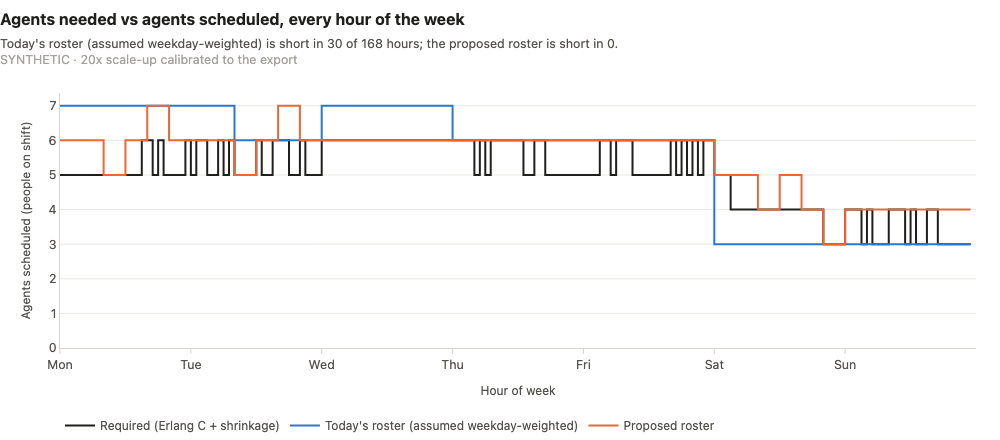

In [14]:
C.fig_requirement_vs_roster(cov)

**What this shows:** the black line is the hourly requirement. Today's assumed roster (blue) sits above it on weekdays and below it for 20 hours on Saturday and 10 on Sunday; the workload-matched roster (orange) follows it all week.

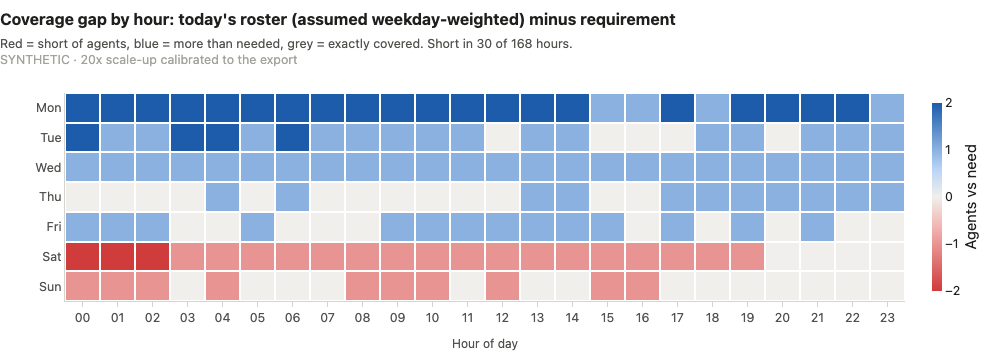

In [15]:
short = cov.loc[cov["scheduled_by_day"] < cov["scheduled_required"], "dow_name"].value_counts()
assert set(short.index) <= {"Sat", "Sun"}                     # every short hour is at the weekend
C.fig_gap_heatmap(cov, "by_day")

**What this shows:** red cells are hours where today's assumed roster is short of the requirement: 30 of 168, all at weekends. Blue cells are spare weekday capacity, the people a re-roster would move to the weekend.

In [16]:
extra = roster.extra_shifts_to_cover(today, required, st["shift_starts"])   # keep today's roster, add shifts
n_extra = int(extra["agents"].sum())
check(n_extra, "staff_hire_extra_shifts_by_day", 0)
check(n_extra / st["shifts_per_fte_week"], "staff_hire_extra_fte_equiv_by_day", 1)
check(roster.fte_from_shifts(n_extra, st["shifts_per_fte_week"]), "staff_hire_extra_fte_by_day", 0)
print(f"Hire option: add {n_extra} shifts = {n_extra / st['shifts_per_fte_week']:.1f} FTE:",
      ", ".join(f"{r.day_name} {r.label} x{r.agents}" for r in extra[extra["agents"] > 0].itertuples()))
D["staff_hire_options"][["hypothesis", "extra_weekly_shifts", "extra_fte_equivalent", "extra_fte",
                         "hours_under_covered_today"]]

Hire option: add 7 shifts = 1.4 FTE: Sat 00:00-08:00 x2, Sat 08:00-16:00 x1, Sat 16:00-00:00 x1, Sun 00:00-08:00 x1, Sun 08:00-16:00 x1, Sun 16:00-00:00 x1


,hypothesis,extra_weekly_shifts,extra_fte_equivalent,extra_fte,hours_under_covered_today
0,flat,5,1.0,1,17
1,by_day,7,1.4,2,30
2,business_hours,14,2.8,3,47


**Reading the hire option:** keeping today's roster and closing every gap by hiring needs 7 extra weekend shifts a week = 1.4 FTE (2 whole hires). Under the other two hypotheses it would be 1 (flat 24/7) or 3 (day-weighted) whole hires.

### 6. Simulated response SLA by roster, under both rules

Loaded from `staff_sim_summary`, written by `staffing.capacity_plan`, which calls `staffing.simulate_roster` for every roster on the same synthetic year (202,172 work items). Columns: the share of contacts reaching an agent within target (queue only), the process ceiling (pickup only), and end-to-end response SLA under each rule. The last two columns compare the simulated live 2-minute service level with the analytic Erlang C check of the same roster.

In [17]:
sim = D["staff_sim_summary"].set_index("roster")
cols = {"fte": "FTE", "utilisation": "utilisation", "queue_sl": "reached agent in target",
        "process_sl": "process ceiling", "response_sl": "response SLA optimistic",
        "response_sl_sum": "response SLA conservative", "live_queue_sl": "live in 2 min: simulation",
        "erlang_live_queue_sl": "live in 2 min: Erlang C"}
for key, col, name in [("staff_sl_today_by_day", "response_sl", "by_day"), ("staff_sl_proposed", "response_sl", "proposed"),
                       ("staff_sl_sum_today_by_day", "response_sl_sum", "by_day"),
                       ("staff_sl_sum_proposed", "response_sl_sum", "proposed"),
                       ("staff_sl_hire_by_day", "response_sl", "hire_by_day"),
                       ("staff_sl_sum_hire_by_day", "response_sl_sum", "hire_by_day"),
                       ("staff_process_ceiling", "process_sl", "proposed"),
                       ("staff_des_live_sl_proposed", "live_queue_sl", "proposed"),
                       ("staff_erlang_live_sl_proposed", "erlang_live_queue_sl", "proposed")]:
    check(sim.loc[name, col], key)
for other, key in [("by_day", "staff_gain_pp_vs_by_day"), ("flat", "staff_gain_pp_vs_flat"),
                   ("business_hours", "staff_gain_pp_vs_business_hours")]:
    check(100 * (sim.loc["proposed", "response_sl"] - sim.loc[other, "response_sl"]), key, 2)
sim[list(cols)].rename(columns=cols).round(4)

,FTE,utilisation,reached agent in target,process ceiling,response SLA optimistic,response SLA conservative,live in 2 min: simulation,live in 2 min: Erlang C
roster,,,,,,,,
proposed,23,0.6739,0.9984,0.8777,0.8761,0.8469,0.9987,0.9976
flat,23,0.6736,0.9892,0.8777,0.8676,0.8266,0.9979,0.9971
by_day,23,0.6756,0.9792,0.8777,0.8581,0.8259,0.9969,0.9962
business_hours,23,0.6741,0.9459,0.8777,0.8273,0.7803,0.9910,0.9881
hire_flat,24,0.6449,0.9980,0.8777,0.8759,0.8497,0.9991,0.9987
hire_by_day,25,0.6351,0.9986,0.8777,0.8764,0.8552,0.9988,0.9985
hire_business_hours,26,0.6013,0.9986,0.8777,0.8765,0.8551,0.9978,0.9978


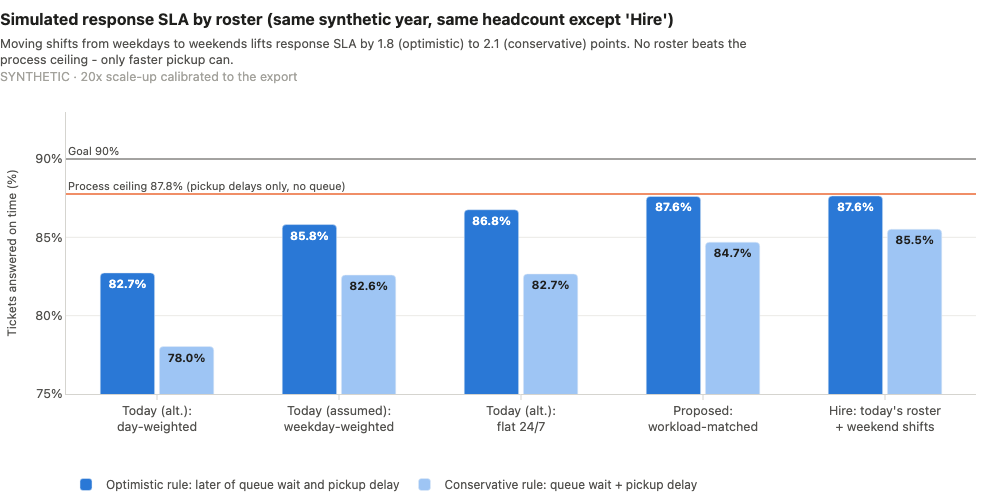

In [18]:
C.fig_roster_sl(D["staff_sim_summary"], cfg["sla"]["goal_attainment"])

**What this shows:** same synthetic year and the same 23 FTE in every bar except Hire. Re-rostering from weekday-weighted to workload-matched lifts response SLA from 85.8% to 87.6% (optimistic) and from 82.6% to 84.7% (conservative). Against the other hypotheses the optimistic gain is +0.8 points (flat 24/7) and +4.9 (day-weighted), so its size depends on what today's roster really is. Every roster sits below the 87.8% process ceiling. The simulation and Erlang C agree on the live queue: 99.9% vs 99.8% of live contacts answered within 2 minutes under the workload-matched roster.

The two rules, recomputed ticket by ticket from `staff_sim_response` ($W$ = simulated queue wait, $D$ = real pickup delay; tickets never answered in their seed count as breaches):

In [19]:
resp = D["staff_sim_response"]
rows = {}
for name in ["by_day", "proposed"]:
    x = resp[resp["roster"] == name]
    W, Dp, target = x["queue_wait_min"], x["pickup_delay_min"].fillna(np.inf), x["response_target_min"]
    rows[name] = {"optimistic: max(W, D) <= target": (np.maximum(W, Dp) <= target).mean(),
                  "conservative: W + D <= target": ((W + Dp) <= target).mean(),
                  "process ceiling: D <= target": (Dp <= target).mean()}
rules = pd.DataFrame(rows).T
check(rules.loc["by_day"].iloc[0], "staff_sl_today_by_day"); check(rules.loc["proposed"].iloc[0], "staff_sl_proposed")
check(rules.loc["by_day"].iloc[1], "staff_sl_sum_today_by_day"); check(rules.loc["proposed"].iloc[1], "staff_sl_sum_proposed")
check(rules.loc["proposed"].iloc[2], "staff_process_ceiling")
rules.round(4)

,"optimistic: max(W, D) <= target",conservative: W + D <= target,process ceiling: D <= target
by_day,0.8581,0.8259,0.8777
proposed,0.8761,0.8469,0.8777


In [20]:
differ = resp[(resp["roster"] == "by_day") & resp["response_met"] & ~resp["response_met_sum"]]
print(f"{len(differ):,} tickets are on time under the optimistic rule but late under the conservative one. First three:")
differ[["channel", "response_target_min", "queue_wait_min", "pickup_delay_min", "response_met", "response_met_sum"]].head(3).round(1)

1,502 tickets are on time under the optimistic rule but late under the conservative one. First three:


,channel,response_target_min,queue_wait_min,pickup_delay_min,response_met,response_met_sum
93490,Email,60.0,22.9,41.5,True,False
93492,Email,60.0,36.5,30.5,True,False
93501,Email,60.0,4.4,55.7,True,False


**Reading the example:** an email (60-minute target) that waited 23 minutes for a free agent and whose real pickup delay was 42 minutes is on time under the optimistic rule (the later of the two is 42 minutes) but late under the conservative rule (64 minutes). The export's on-time response times are spread evenly inside the target window, so adding any queue wait pushes many of them over the line. That is why the conservative rule is lower for every roster.

Average items waiting over the simulated year:
 weekend   weekday hours  weekend hours
roster                                
by_day              1.1           11.0
proposed            1.6            1.1


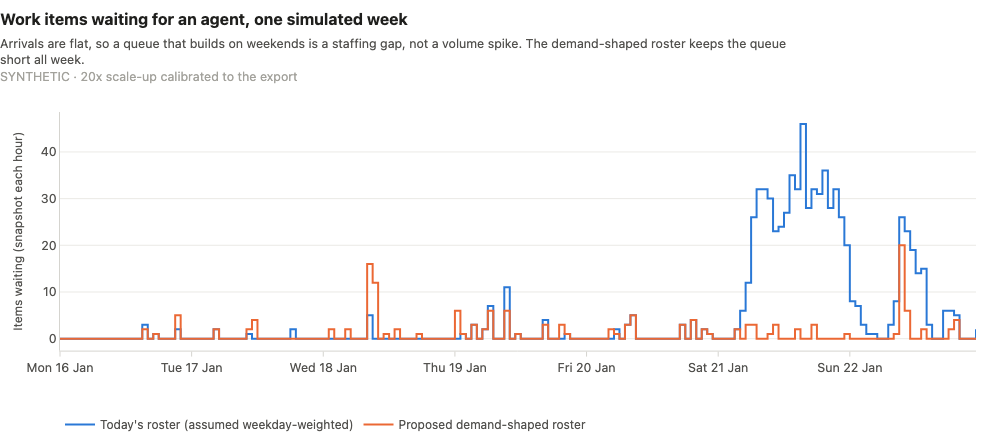

In [21]:
hourly = D["staff_sim_hourly"]
weekend = (pd.Timestamp("2023-01-01") + pd.to_timedelta(hourly["hour_index"], unit="h")).dt.day_of_week >= 5
avg_queue = (hourly.assign(weekend=weekend.map({False: "weekday hours", True: "weekend hours"}))
             .query("roster in ['by_day', 'proposed']").groupby(["roster", "weekend"])["queue_len"].mean().unstack())
print("Average items waiting over the simulated year:\n", avg_queue.round(1).to_string())
C.fig_sim_queue_week(hourly, demand)

**What this shows:** one simulated week (16–22 January). Under today's assumed roster the queue builds every weekend, when follow-up work outruns the few people on shift; under the workload-matched roster it stays short all week. Over the whole simulated year, today's assumed roster averages 11.0 items waiting in weekend hours vs 1.1 on weekdays; the workload-matched roster 1.1 vs 1.6. Arrivals are flat, so this is a staffing gap, not a volume spike.

### 7. Replications: is the ranking a random-draw artefact?

`staff_replications` (from `business_case.replicate_rosters`) re-runs the comparison on 5 independent synthetic years: new arrivals, new bootstrap draws, new handle times, new staffing noise. The rosters are held fixed.

In [22]:
reps = D["staff_replications"]
opt = reps.pivot(index="replication", columns="roster", values="response_sl")
con = reps.pivot(index="replication", columns="roster", values="response_sl_sum")
gain = pd.DataFrame({"re-roster gain, optimistic (pts)": 100 * (opt["proposed"] - opt["by_day"]),
                     "re-roster gain, conservative (pts)": 100 * (con["proposed"] - con["by_day"]),
                     "hire minus re-roster, optimistic (pts)": 100 * (opt["hire_by_day"] - opt["proposed"]),
                     "hire minus re-roster, conservative (pts)": 100 * (con["hire_by_day"] - con["proposed"])})
for col, key in zip(gain.columns, ["rep_gain_pp_vs_by_day", "rep_gain_pp_vs_by_day_sum",
                                   "rep_hire_minus_reroster_pp", "rep_hire_minus_reroster_pp_sum"]):
    check(gain[col].min(), f"{key}_min", 2); check(gain[col].max(), f"{key}_max", 2)
stable = all(((t["proposed"] > t["by_day"]) & (t["by_day"] > t["business_hours"])).all() for t in (opt, con))
assert stable == (kn["rep_ranking_stable"] and kn["rep_ranking_stable_sum"])
print("Workload-matched > weekday-weighted > day-weighted in every replication, under both rules:", stable)
gain.round(2)

Workload-matched > weekday-weighted > day-weighted in every replication, under both rules: True


,"re-roster gain, optimistic (pts)","re-roster gain, conservative (pts)","hire minus re-roster, optimistic (pts)","hire minus re-roster, conservative (pts)"
replication,,,,
1,1.74,1.32,0.10,1.36
2,1.96,1.92,0.09,1.08
3,1.50,1.37,0.18,1.43
4,1.81,1.79,0.17,1.09
5,1.97,1.81,0.12,1.28


**What this shows:** in every one of the 5 synthetic years the workload-matched roster beats today's assumed roster, by +1.5 to +2.0 points (optimistic) and +1.3 to +1.9 (conservative), and the order of rosters never changes. Hiring on top of today's roster beats re-rostering by only +0.1 to +0.2 points under the optimistic rule and +1.1 to +1.4 under the conservative rule, for 1.4 FTE more.

### 8. Stress test: weekend follow-ups wait until Monday

The weekend gap exists because the model does follow-up work when it arises, including at weekends. `staff_sim_summary_deferred` re-runs the whole capacity plan (`staffing.capacity_plan(..., follow_up_timing="weekdays")`) with every follow-up that would land on a Saturday or Sunday moved to Monday, same time of day. The workload-matched roster is re-optimised for that demand, and every roster gets the resulting headcount.

In [23]:
base = D["staff_sim_summary"].set_index("roster")
dfr = D["staff_sim_summary_deferred"].set_index("roster")
check(dfr.loc["proposed", "fte"], "deferred_fte", 0)
g_opt = check(100 * (dfr.loc["proposed", "response_sl"] - dfr.loc["by_day", "response_sl"]), "deferred_gain_pp_vs_by_day", 2)
g_con = check(100 * (dfr.loc["proposed", "response_sl_sum"] - dfr.loc["by_day", "response_sl_sum"]),
              "deferred_gain_pp_vs_by_day_sum", 2)
print(f"Stress test: {int(dfr.loc['proposed', 'fte'])} FTE; re-roster gain {g_opt:+.1f} (optimistic), {g_con:+.1f} (conservative) pts")
items = D["synth_work_items"]
fu = items[items["kind"] == "follow_up"]
never = ~syn.set_index("ticket_id")["resolution_outcome"].reindex(fu["ticket_id"]).str.startswith("Resolved").to_numpy()
print(f"Follow-up work from never-resolved tickets (compressed into 6 days in the model): "
      f"{fu['service_s'].to_numpy()[never].sum() / fu['service_s'].sum():.0%}")
order = ["by_day", "flat", "business_hours", "proposed", "hire_by_day"]
pd.DataFrame({"base, optimistic": base.loc[order, "response_sl"], "base, conservative": base.loc[order, "response_sl_sum"],
              "stress, optimistic": dfr.loc[order, "response_sl"], "stress, conservative": dfr.loc[order, "response_sl_sum"],
              "stress, email p95 queue wait (min)": dfr.loc[order, "p95_queue_wait_min_email"]}).round(4)

Stress test: 24 FTE; re-roster gain +2.3 (optimistic), -2.1 (conservative) pts
Follow-up work from never-resolved tickets (compressed into 6 days in the model): 18%


,"base, optimistic","base, conservative","stress, optimistic","stress, conservative","stress, email p95 queue wait (min)"
roster,,,,,
by_day,0.8581,0.8259,0.7911,0.7668,220.5125
flat,0.8676,0.8266,0.7124,0.6890,536.6815
business_hours,0.8273,0.7803,0.7825,0.7381,186.2186
proposed,0.8761,0.8469,0.8137,0.7460,115.7067
hire_by_day,0.8764,0.8552,0.8763,0.8613,9.9709


**What this shows:** if weekend follow-ups wait until Monday, Monday work piles up under every roster and email queues grow. The re-roster gain becomes +2.3 points under the optimistic rule but -2.1 under the conservative rule. So the gain depends on how weekend work is handled today. Before moving shifts, check the real roster and whether weekend follow-ups are worked at weekends.

### 9. Sensitivity: which assumptions move the headcount answer?

`staff_sensitivity` (from `staffing.sensitivity`) changes one assumption at a time and re-runs requirement → cheapest roster → FTE. The rows that only need the cached demand are recomputed here as a check; the rows that change what "agent interactions" means need new work items and are loaded.

In [24]:
def fte_for(**kw):
    """Cheapest-roster FTE for the cached demand with one assumption changed."""
    req_kw = staffing.requirement(demand, st, **kw)
    return staffing.min_fte_for_requirement(req_kw, st["shift_starts"], st["shifts_per_fte_week"])[1]

recomputed = {"sens_fte_aht_low": fte_for(aht_factor=0.7), "sens_fte_aht_high": fte_for(aht_factor=1.3),
              "sens_fte_goal_80": fte_for(sl_goal=0.80), "sens_fte_goal_95": fte_for(sl_goal=0.95),
              "sens_fte_scale_10x": fte_for(volume_factor=0.5), "sens_fte_scale_40x": fte_for(volume_factor=2.0),
              "sens_fte_two_pool": fte_for(model="two_pool")}
for key, value in recomputed.items():
    check(value, key, 0)
print("Recomputed FTE:", recomputed)
sens = D["staff_sensitivity"]
sens[["parameter", "value", "fte_demand_shaped", "delta_fte_vs_base", "extra_fte_if_today_roster_kept",
      "peak_scheduled_per_hour", "min_scheduled_per_hour"]]

Recomputed FTE: {'sens_fte_aht_low': 16, 'sens_fte_aht_high': 28, 'sens_fte_goal_80': 23, 'sens_fte_goal_95': 23, 'sens_fte_scale_10x': 13, 'sens_fte_scale_40x': 42, 'sens_fte_two_pool': 37}


,parameter,value,fte_demand_shaped,delta_fte_vs_base,extra_fte_if_today_roster_kept,peak_scheduled_per_hour,min_scheduled_per_hour
0,Base case,base,23,0,2,6,3
1,Meaning of 'agent interactions',half_agent,19,-4,0,5,3
2,Meaning of 'agent interactions',chat_in_session,19,-4,0,5,3
3,Handle time per touch,x0.7,16,-7,0,4,2
4,Handle time per touch,x1.3,28,5,6,8,4
5,Shrinkage,20%,19,-4,1,5,3
6,Shrinkage,40%,26,3,3,7,4
7,Max occupancy,80%,23,0,2,7,3
8,Max occupancy,90%,22,-1,2,6,3
9,"Service-level goal (live, 2 min)",80%,23,0,2,6,3


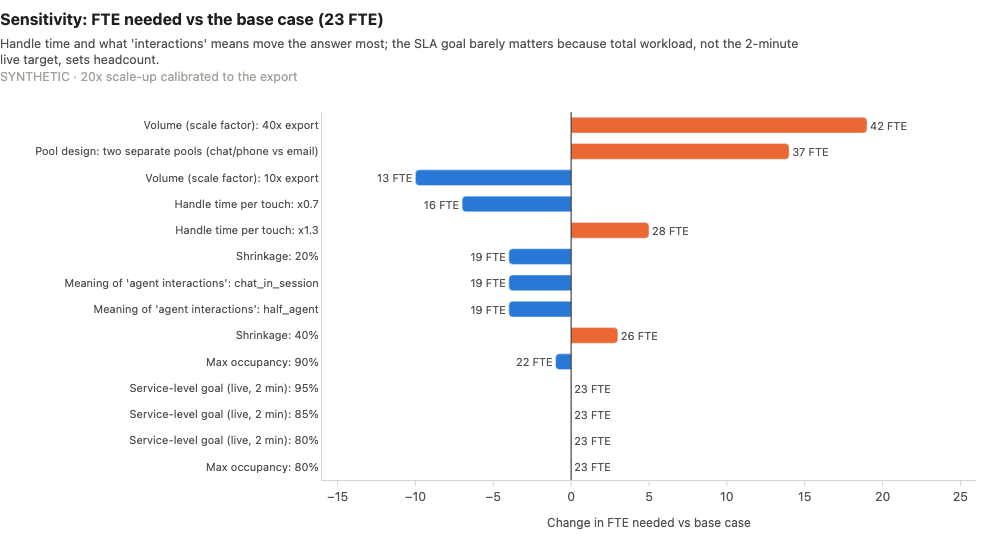

In [25]:
C.fig_sensitivity(sens)

**What this shows:** handle time is the assumption that matters most: ±30% moves the answer from 16 to 28 FTE. A narrower reading of "agent interactions" gives 19. Two separate teams for chat/phone and email would need 37, because two small teams lose the pooling effect: each is staffed for its own randomness and its own 24/7 minimum. At 10× or 40× the export's volume the answer is 13 or 42. Changing the live SLA goal between 80% and 95% changes nothing (23 and 23 FTE), because total workload binds first. The column "extra FTE if today's roster is kept" is the hire-instead cost under each assumption.

### 10. Growth: how much volume can the same roster absorb?

`staff_growth` (from `business_case.simulate_growth`) re-generates the synthetic year at +5% to +50% volume with the same random seeds and simulates it with the workload-matched roster held fixed, without and with base-case deflection (notebook 05). The staffing goal: at least 90% of contacts reach an agent within target, and utilisation stays at or below 85%.

In [26]:
growth = D["staff_growth"]

def holds_until(g):
    """Largest tested growth at which the staffing goal still holds (same rule as the pipeline)."""
    ok = ((g["queue_sl"] >= st["sl_goal"]) & (g["utilisation"] <= st["max_occupancy"])).to_numpy()
    n_ok = len(ok) if ok.all() else int(np.argmin(ok))
    return float(g["volume_factor"].iloc[n_ok - 1] - 1), bool(ok.all())

for level, key in [("none", "growth_holds_until_no_deflection"), ("base", "growth_holds_until_with_deflection")]:
    until, range_end = holds_until(growth[growth["deflection"] == level])
    check(until, key, 2)
    assert range_end == kn[f"{key}_is_range_end"]
    print(f"deflection = {level}: staffing goal met up to +{until:.0%} volume" + (" (top of tested range)" if range_end else ""))
growth.pivot(index="volume_factor", columns="deflection",
             values=["queue_sl", "utilisation", "response_sl", "response_sl_sum"]).round(3)

deflection = none: staffing goal met up to +25% volume
deflection = base: staffing goal met up to +50% volume (top of tested range)


queue_sl        utilisation        response_sl        response_sl_sum       
deflection        base   none        base   none        base   none            base   none
volume_factor                                                                             
1.00             1.000  0.998       0.542  0.674       0.879  0.876           0.868  0.847
1.05             0.999  0.996       0.575  0.715       0.874  0.870           0.861  0.831
1.10             0.999  0.987       0.599  0.747       0.874  0.861           0.857  0.807
1.15             0.999  0.977       0.631  0.784       0.872  0.850           0.849  0.787
1.20             0.998  0.941       0.658  0.819       0.874  0.821           0.847  0.746
1.25             0.997  0.922       0.681  0.847       0.870  0.799           0.840  0.711
1.30             0.996  0.849       0.709  0.885       0.872  0.733           0.833  0.641
1.40             0.986  0.589       0.769  0.952       0.863  0.493           0.803  0.459
1.50             0.956  0.475       0.820  1.022       0.836  0.388           0.753  0.386

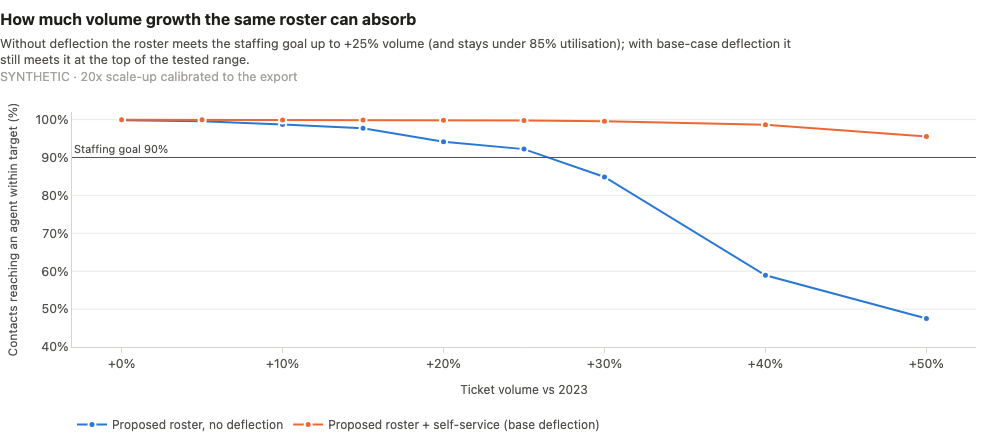

In [27]:
C.fig_growth(growth, st["sl_goal"], st["max_occupancy"])

**What this shows:** without deflection the workload-matched roster meets the staffing goal up to +25% volume; at +30% fewer than 90% of contacts reach an agent in time and utilisation passes 85%. With base-case deflection it still meets the goal at +50%, the top of the tested range. End-to-end response SLA slips earlier, because queue waits come on top of the real pickup delays: under the optimistic rule it falls from 87.6% today to 86.1% at +10% and 79.9% at +25% (to 71.1% at +25% under the conservative rule; table above). Weekly response SLA should therefore be watched alongside the volume trigger.

## Limitations

- **A planning scenario, not today's team.** Every number here is for a 20× version of the export. The model cannot say whether the real team is short; only the real-data tests in notebook 03 can, and they show no capacity signal. The FTE answer scales with the scenario: 13 FTE at 10×, 42 at 40×.
- **Handle time is assumed** (12 / 10 / 8 minutes for a first chat / phone / email touch, 6 per follow-up) and moves headcount most: 16–28 FTE for ±30%. What "agent interactions" counts is also uncertain (19 FTE under a narrower reading).
- **No intraday shape.** Arrivals in the export are flat across the 24 hours, which is unusual for a European B2B desk. A real desk with a daytime peak would get a different, probably larger, re-roster effect.
- **Today's roster is unknown.** Across the three hypotheses the optimistic re-roster gain ranges from +0.8 to +4.9 points. The weekday-weighted baseline is an assumption to check with WFM.
- **How queue wait and pickup delay combine is unknown,** so every result is bracketed by the optimistic and conservative rules.
- **Follow-up timing is modelled, not observed.** Follow-ups are spread evenly over each ticket's life; never-resolved tickets have theirs compressed into 6 days (18% of follow-up work, §8). Deferring weekend follow-ups to Monday flips the sign of the conservative gain.
- **Model simplifications.** Erlang C assumes Poisson arrivals, exponential handle times, no abandonment and a steady state within each hour. The simulation relaxes the last three (lognormal handle times, carry-over between hours, live work pre-empting email work) but keeps no abandonment, one blended pool and a flat 30% shrinkage. Rosters are shift counts, not named rotas: days off, preferences and contracts are not modelled.

## Recommendations

- **WFM / scheduling + team leads: check today's real roster and how weekend follow-ups are handled, then re-roster toward workload.** Impact [SYNTHETIC]: same headcount, response SLA +1.5 to +2.0 points (optimistic) / +1.3 to +1.9 (conservative), if today's roster is weekday-weighted. Measure: response SLA and queue wait by hour of week; weekend vs weekday response SLA. Risk: the real roster may differ; weekend shifts need staff agreement; the gain is not robust if weekend follow-ups wait until Monday.
- **Support Director: no headcount request this quarter on staffing grounds; revisit at a defined trigger.** Impact: avoids ~€94k in year one for the hire option, which buys at most +1.4 points more than re-rostering. Measure: weekly volume vs 2023 (trigger: sustained > +25%), contacts reaching an agent within target (trigger: < 90%), agent utilisation (trigger: > 85%), with weekly response SLA alongside. Risk: volume grows faster than expected; mitigated by the trigger and by deflection headroom (notebook 05).
- **Team leads + support-tooling owner: work on pickup, not only on the roster.** Impact: no roster lifts response SLA above the 87.8% process ceiling; only faster pickup can (email alert and push routing, notebook 05). Measure: share of emails answered within 60 minutes; chat/phone pickup time. Risk: alert fatigue.
- **Ops Analytics: replace the assumptions with real inputs and re-run `make all`.** Impact: turns the planning scenario into a plan. Inputs, in order of sensitivity: handle time from agent activity logs, the real roster and headcount, how weekend follow-ups are handled today. Risk: data access takes longer than the planning cycle; until then quote headcount as a range (16–28 FTE in the 20× scenario), not a point.